# Forest Cover Type Prediction
## PRCP-1005 | Machine Learning Classification

**Objective:** Predict one of seven forest cover types using cartographic and environmental variables.

This notebook provides a reproducible workflow covering data validation, exploratory data analysis, preprocessing justification, repeated cross-validation, hyperparameter tuning, final evaluation, error analysis and model interpretation.

**Important validation note:** This dataset was used in earlier project iterations. The revised holdout and cross-validation results must therefore not be described as a completely independent historical evaluation.


## 1. Imports and project configuration

In [1]:
from pathlib import Path
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
    cross_validate, RandomizedSearchCV
)
from sklearn.metrics import (
    accuracy_score, f1_score, balanced_accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline

warnings.filterwarnings("default")
RANDOM_STATE = 42

ROOT = Path.cwd()
if not (ROOT / "data" / "train.csv").exists() and (ROOT.parent / "data" / "train.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "train.csv"
REPORTS = ROOT / "reports"
CHARTS = REPORTS / "charts"
MODELS = ROOT / "models"

for folder in [REPORTS, CHARTS, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 70)
pd.set_option("display.width", 140)

print("Project directory:", ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())


Project directory: C:\Rakesh Project\Forest-Cover-Prediction
Dataset path: C:\Rakesh Project\Forest-Cover-Prediction\data\train.csv
Dataset exists: True


## 2. Load and validate the dataset

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.value_counts().rename("Column count").to_frame())


Dataset shape: (15120, 56)


,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,6279,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,6225,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,6121,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,6211,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,6172,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5


,Column count
int64,56


In [3]:
target_col = "Cover_Type"
id_col = "Id"

required_columns = {target_col, id_col}
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(f"Required columns missing: {missing_required}")

print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate identifiers:", int(df[id_col].duplicated().sum()))
print("Target classes:", sorted(df[target_col].unique()))
print("\nTarget counts:")
display(df[target_col].value_counts().sort_index().to_frame("Records"))


Missing values: 0
Duplicate rows: 0
Duplicate identifiers: 0
Target classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Target counts:


,Records
Cover_Type,
1,2160
2,2160
3,2160
4,2160
5,2160
6,2160
7,2160


## 3. Data quality and structural checks

In [4]:
missing_summary = df.isna().sum().sort_values(ascending=False)
constant_columns = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]

audit = pd.DataFrame({
    "Check": [
        "Rows", "Columns", "Missing cells", "Duplicate rows",
        "Duplicate Id values", "Constant columns"
    ],
    "Result": [
        len(df), df.shape[1], int(df.isna().sum().sum()),
        int(df.duplicated().sum()), int(df[id_col].duplicated().sum()),
        ", ".join(constant_columns) if constant_columns else "None"
    ]
})
display(audit)

print("Constant column values:")
for col in constant_columns:
    print(f"{col}: {df[col].iloc[0]}")


,Check,Result
0,Rows,15120
1,Columns,56
2,Missing cells,0
3,Duplicate rows,0
4,Duplicate Id values,0
5,Constant columns,"Soil_Type7, Soil_Type15"


Constant column values:
Soil_Type7: 0
Soil_Type15: 0


### Data quality interpretation

Missing values are checked before modelling. Imputation is not required when the dataset contains no missing observations. Duplicate records and identifier uniqueness are checked separately.

The identifier is excluded because it is a record reference rather than an environmental predictor. Constant predictors contain no variation and cannot help distinguish target classes, so they are excluded from model training. These decisions are based on observed dataset properties, not assumptions.


In [5]:
# Identify predictor groups from the dataset schema.
continuous_candidates = [
    "Elevation", "Aspect", "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]
continuous_cols = [c for c in continuous_candidates if c in df.columns]
wilderness_cols = [c for c in df.columns if c.startswith("Wilderness_Area")]
soil_cols = [c for c in df.columns if c.startswith("Soil_Type")]

print("Continuous environmental features:", len(continuous_cols))
print("Wilderness indicator features:", len(wilderness_cols))
print("Soil indicator features:", len(soil_cols))


Continuous environmental features: 10
Wilderness indicator features: 4
Soil indicator features: 40


## 4. Target distribution

,Records,Percentage
Cover_Type,,
1,2160,14.29
2,2160,14.29
3,2160,14.29
4,2160,14.29
5,2160,14.29
6,2160,14.29
7,2160,14.29


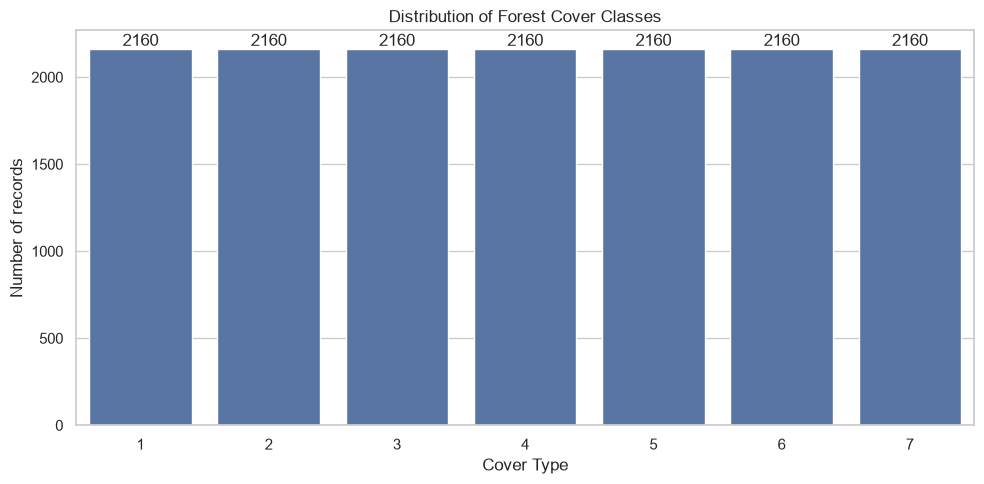

In [6]:
target_counts = df[target_col].value_counts().sort_index()
target_percent = (target_counts / len(df) * 100).round(2)

target_summary = pd.DataFrame({
    "Records": target_counts,
    "Percentage": target_percent
})
display(target_summary)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=target_counts.index.astype(str), y=target_counts.values, ax=ax)
ax.set(title="Distribution of Forest Cover Classes", xlabel="Cover Type", ylabel="Number of records")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig(CHARTS / "01_target_distribution.png", dpi=180, bbox_inches="tight")
plt.show()


### Target distribution interpretation

The supplied dataset contains 15,120 records, with 2,160 records in each of the seven classes. The target is therefore exactly balanced in this dataset. Accuracy is useful, but macro F1 and balanced accuracy are also reported to show performance across all classes.


## 5. Wilderness and soil indicator analysis

Indicator values other than 0/1: None
Wilderness indicators: row-sum counts


,Rows
1,15120


Soil indicators: row-sum counts


,Rows
1,15120


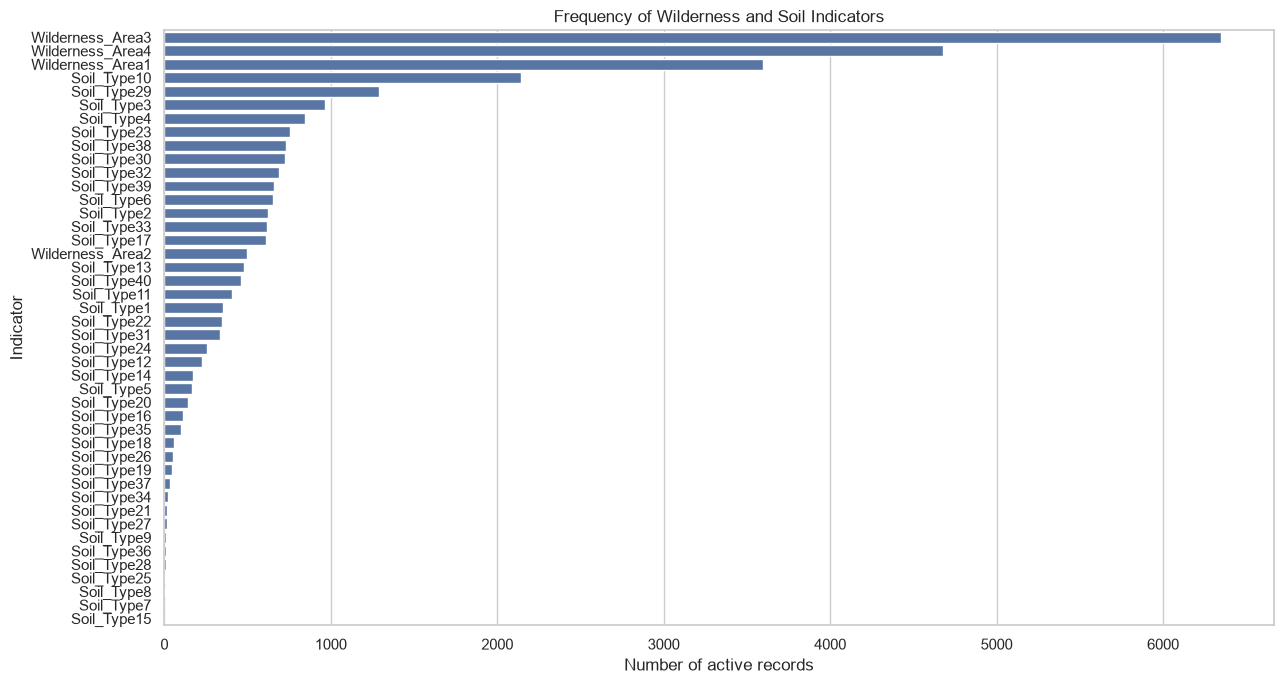

In [7]:
indicator_cols = wilderness_cols + soil_cols

if indicator_cols:
    invalid_binary = {
        col: sorted(set(df[col].dropna().unique()) - {0, 1})
        for col in indicator_cols
    }
    invalid_binary = {k: v for k, v in invalid_binary.items() if v}

    print("Indicator values other than 0/1:", invalid_binary or "None")

    if wilderness_cols:
        wilderness_row_sums = df[wilderness_cols].sum(axis=1)
        print("Wilderness indicators: row-sum counts")
        display(wilderness_row_sums.value_counts().sort_index().to_frame("Rows"))

    if soil_cols:
        soil_row_sums = df[soil_cols].sum(axis=1)
        print("Soil indicators: row-sum counts")
        display(soil_row_sums.value_counts().sort_index().to_frame("Rows"))

    prevalence = df[indicator_cols].sum().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(13, 7))
    sns.barplot(x=prevalence.values, y=prevalence.index, ax=ax)
    ax.set(title="Frequency of Wilderness and Soil Indicators", xlabel="Number of active records", ylabel="Indicator")
    plt.tight_layout()
    plt.savefig(CHARTS / "02_indicator_frequency.png", dpi=180, bbox_inches="tight")
    plt.show()


### Indicator interpretation and encoding decision

Wilderness and soil categories are already represented as binary indicator columns. They do not require additional one-hot encoding. The row-sum checks verify whether each observation has exactly one active wilderness category and one active soil category.

Tree-based algorithms can work directly with these numeric indicator columns. No scaling is required for the tree-based candidate models used here.


## 6. Numerical feature distributions and descriptive statistics

,count,mean,std,min,25%,50%,75%,max,skewness
Elevation,15120.0,2749.323,417.678,1863.0,2376.0,2752.0,3104.00,3849.0,0.076
Aspect,15120.0,156.677,110.086,0.0,65.0,126.0,261.00,360.0,0.451
Slope,15120.0,16.502,8.454,0.0,10.0,15.0,22.00,52.0,0.524
Horizontal_Distance_To_Hydrology,15120.0,227.196,210.075,0.0,67.0,180.0,330.00,1343.0,1.488
Vertical_Distance_To_Hydrology,15120.0,51.077,61.239,-146.0,5.0,32.0,79.00,554.0,1.538
Horizontal_Distance_To_Roadways,15120.0,1714.023,1325.066,0.0,764.0,1316.0,2270.00,6890.0,1.248
Hillshade_9am,15120.0,212.704,30.561,0.0,196.0,220.0,235.00,254.0,-1.094
Hillshade_Noon,15120.0,218.966,22.802,99.0,207.0,223.0,235.00,254.0,-0.953
Hillshade_3pm,15120.0,135.092,45.895,0.0,106.0,138.0,167.00,248.0,-0.341
Horizontal_Distance_To_Fire_Points,15120.0,1511.147,1099.936,0.0,730.0,1256.0,1988.25,6993.0,1.617


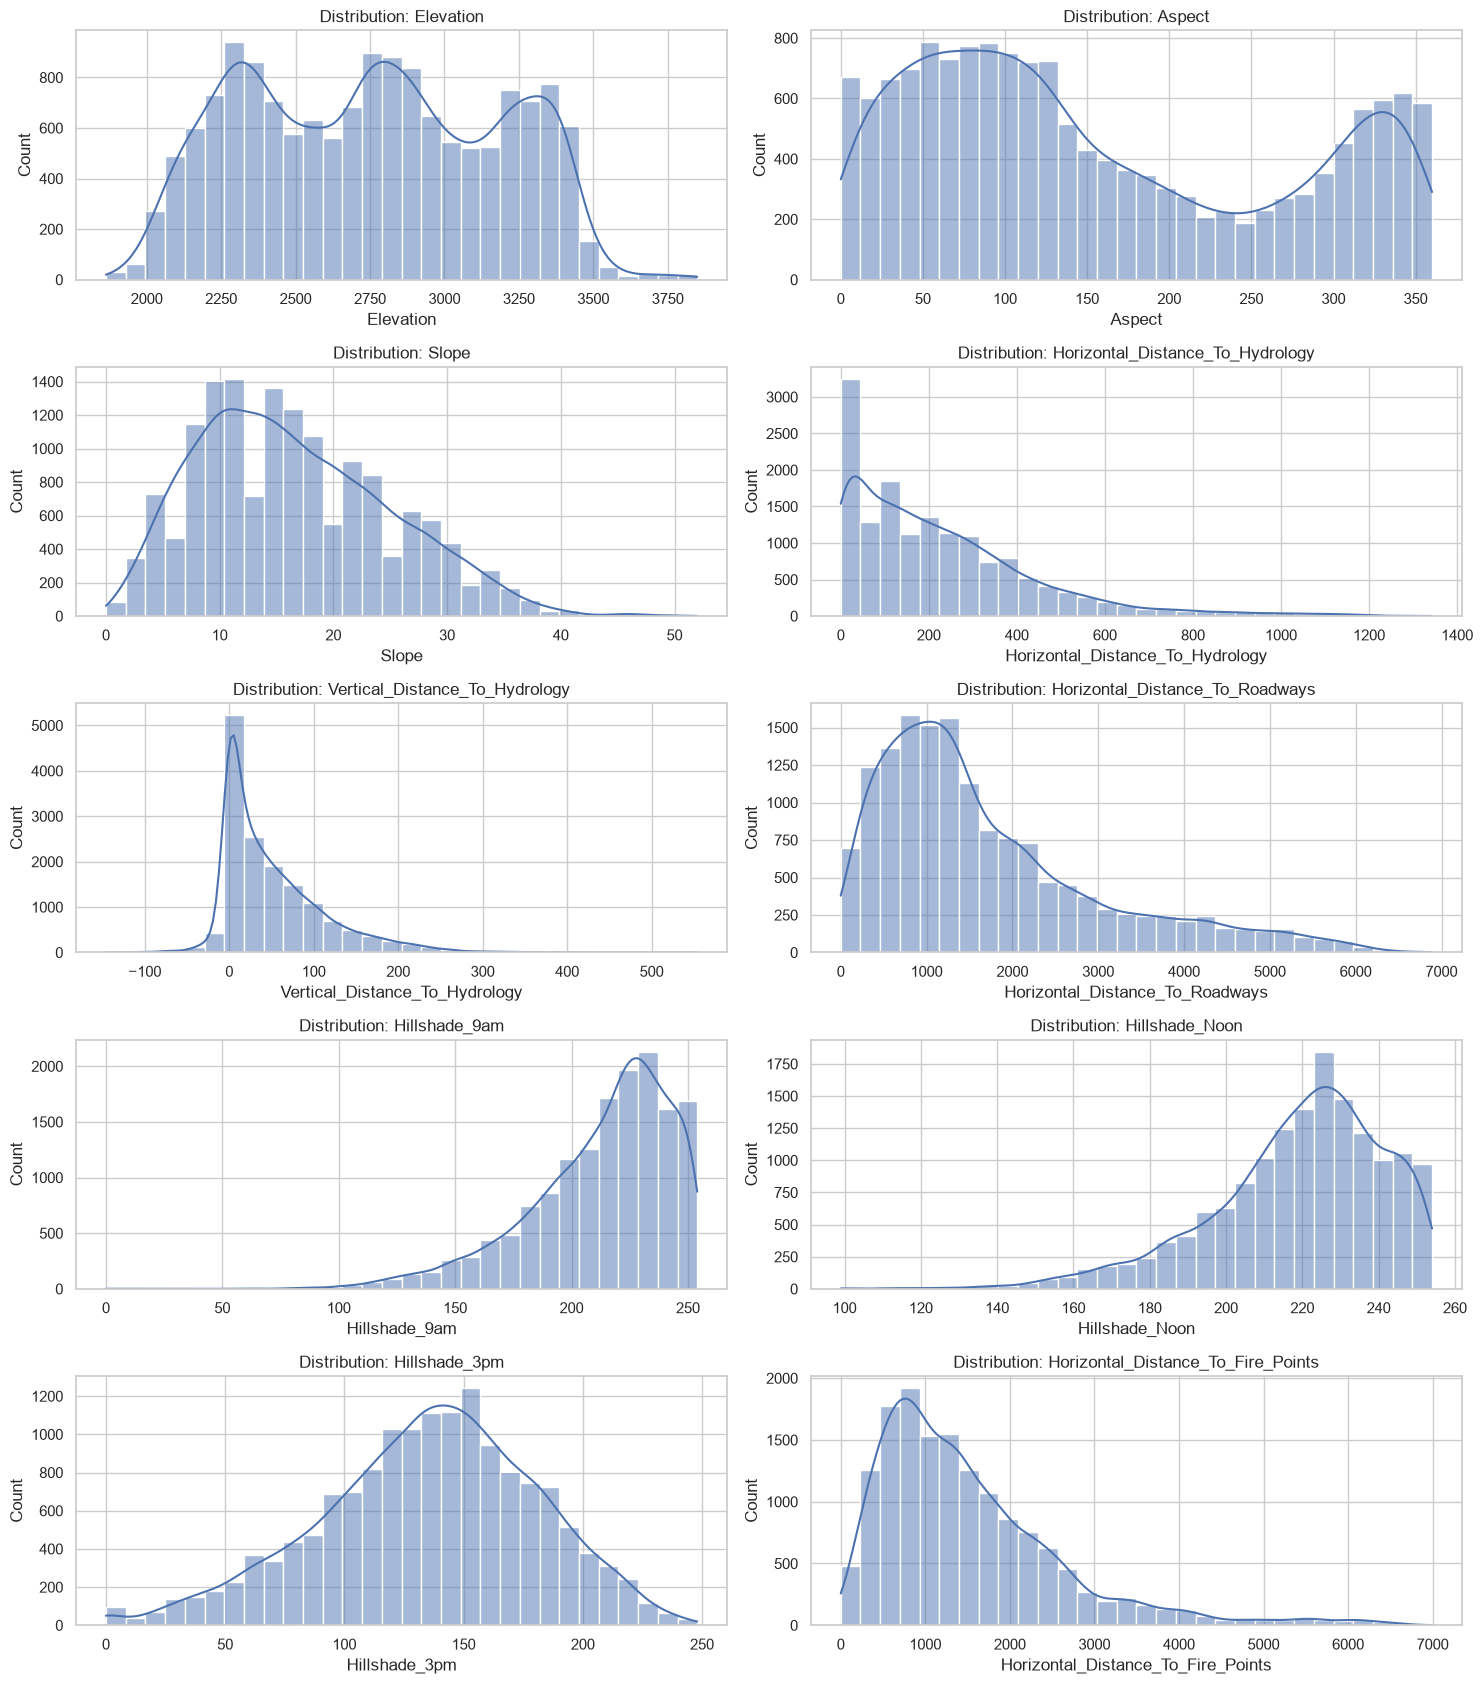

In [8]:
numeric_summary = df[continuous_cols].describe().T
numeric_summary["skewness"] = df[continuous_cols].skew()
display(numeric_summary.round(3))

n = len(continuous_cols)
cols = 2
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3.4))
axes = np.array(axes).reshape(-1)

for i, col in enumerate(continuous_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], bins=30)
    axes[i].set_title(f"Distribution: {col}")
    axes[i].set_xlabel(col)

for j in range(n, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig(CHARTS / "03_numeric_feature_distributions.png", dpi=180, bbox_inches="tight")
plt.show()


## 7. Outlier assessment

In [9]:
outlier_rows = []
for col in continuous_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_rows.append({
        "Feature": col, "Q1": q1, "Q3": q3,
        "IQR": iqr, "Lower fence": lower,
        "Upper fence": upper, "Potential outliers": count,
        "Outlier percentage": count / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values(
    "Outlier percentage", ascending=False
)
display(outlier_summary.round(2))
outlier_summary.to_csv(REPORTS / "outlier_summary.csv", index=False)


,Feature,Q1,Q3,IQR,Lower fence,Upper fence,Potential outliers,Outlier percentage
5,Horizontal_Distance_To_Roadways,764.0,2270.00,1506.00,-1495.00,4529.00,830,5.49
9,Horizontal_Distance_To_Fire_Points,730.0,1988.25,1258.25,-1157.38,3875.62,645,4.27
4,Vertical_Distance_To_Hydrology,5.0,79.00,74.00,-106.00,190.00,586,3.88
3,Horizontal_Distance_To_Hydrology,67.0,330.00,263.00,-327.50,724.50,512,3.39
6,Hillshade_9am,196.0,235.00,39.00,137.50,293.50,408,2.70
7,Hillshade_Noon,207.0,235.00,28.00,165.00,277.00,393,2.60
8,Hillshade_3pm,106.0,167.00,61.00,14.50,258.50,124,0.82
2,Slope,10.0,22.00,12.00,-8.00,40.00,57,0.38
1,Aspect,65.0,261.00,196.00,-229.00,555.00,0,0.00
0,Elevation,2376.0,3104.00,728.00,1284.00,4196.00,0,0.00


### Outlier treatment decision

The IQR rule is used to flag unusual numerical observations, not automatically delete them. Environmental measurements can legitimately contain extreme values, and tree-based models are generally less sensitive to feature scaling and extreme magnitudes than distance-based models. The observations are retained unless a separate data-quality investigation establishes that a value is erroneous.


## 8. Correlation analysis

C:\Rakesh Project\Forest-Cover-Prediction\.venv\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


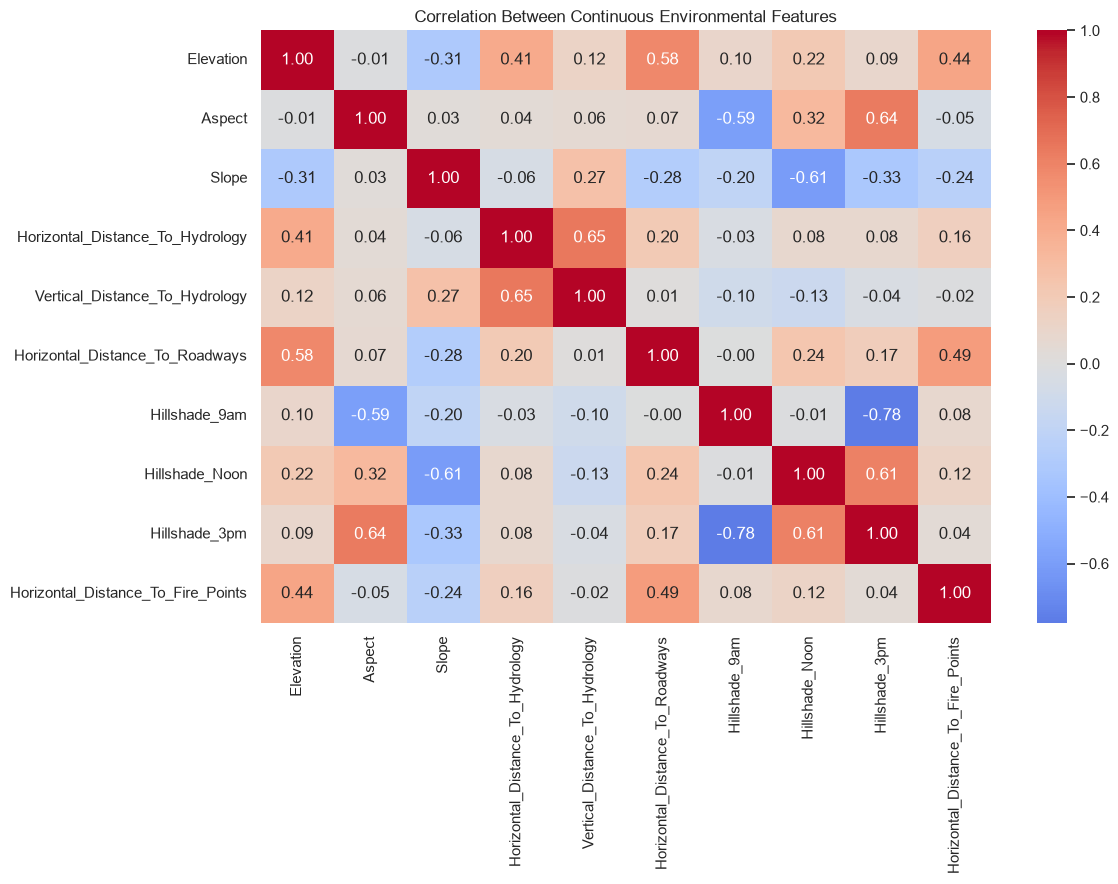

Correlation
Hillshade_9am                    Hillshade_3pm                         -0.779965
Horizontal_Distance_To_Hydrology Vertical_Distance_To_Hydrology         0.652142
Aspect                           Hillshade_3pm                          0.635022
Hillshade_Noon                   Hillshade_3pm                          0.614526
Slope                            Hillshade_Noon                        -0.612613
Aspect                           Hillshade_9am                         -0.593997
Elevation                        Horizontal_Distance_To_Roadways        0.578659
Horizontal_Distance_To_Roadways  Horizontal_Distance_To_Fire_Points     0.486386
Elevation                        Horizontal_Distance_To_Fire_Points     0.443563
                                 Horizontal_Distance_To_Hydrology       0.412712

Correlation
Horizontal_Distance_To_Fire_Points Elevation                                   NaN
                                   Aspect                                      NaN
                                   Slope                                       NaN
                                   Horizontal_Distance_To_Hydrology            NaN
                                   Vertical_Distance_To_Hydrology              NaN
                                   Horizontal_Distance_To_Roadways             NaN
                                   Hillshade_9am                               NaN
                                   Hillshade_Noon                              NaN
                                   Hillshade_3pm                               NaN
                                   Horizontal_Distance_To_Fire_Points          NaN

In [10]:
corr = df[continuous_cols].corr()
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Correlation Between Continuous Environmental Features")
plt.tight_layout()
plt.savefig(CHARTS / "04_continuous_feature_correlation.png", dpi=180, bbox_inches="tight")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
correlation_pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
display(correlation_pairs.head(10).rename("Correlation").to_frame())
display(correlation_pairs.tail(10).rename("Correlation").to_frame())


### Correlation interpretation

Correlation measures linear association between numerical features; it does not demonstrate causation. Strongly correlated predictors may contain overlapping information. Tree ensembles can still use correlated variables, but impurity-based importance may distribute importance across related predictors.


## 9. Feature relationships with forest cover type

C:\Rakesh Project\Forest-Cover-Prediction\.venv\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


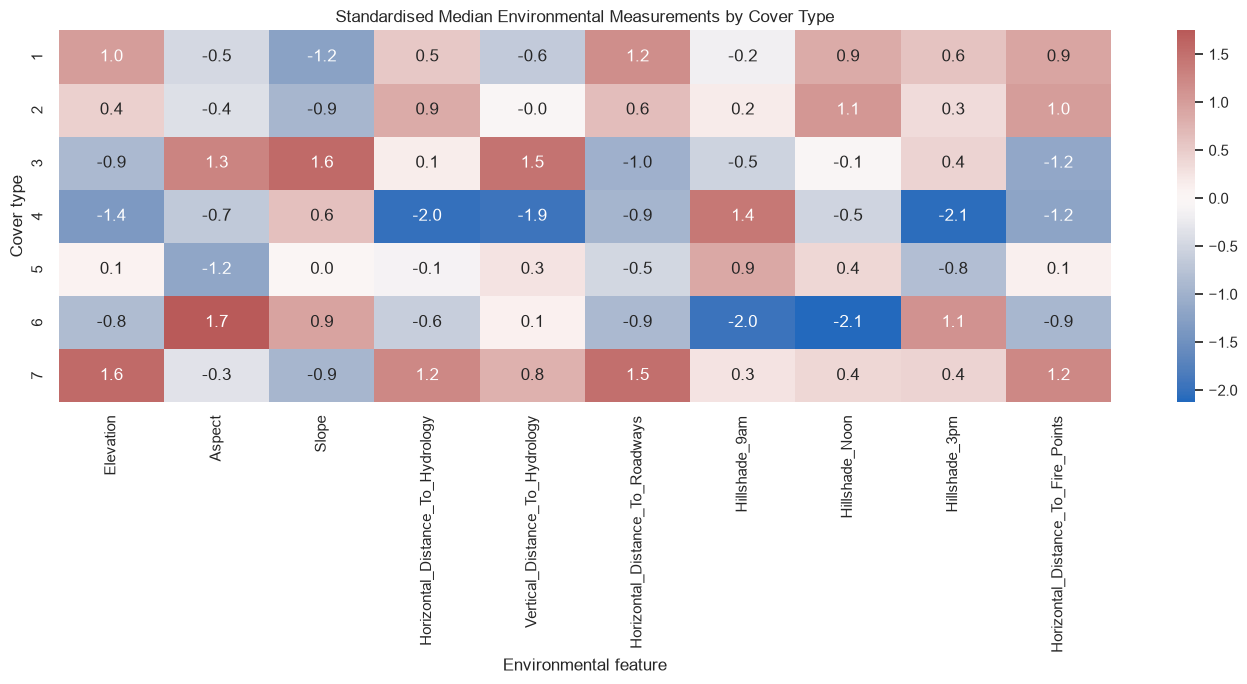

C:\Rakesh Project\Forest-Cover-Prediction\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


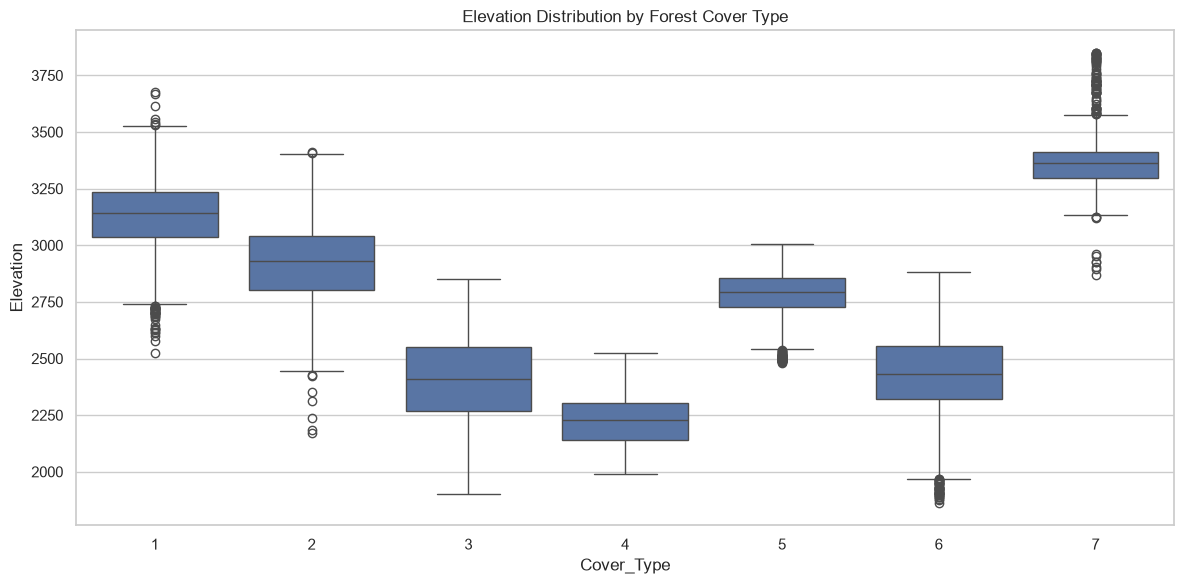

In [11]:
class_medians = df.groupby(target_col)[continuous_cols].median()
class_z = (class_medians - class_medians.mean()) / class_medians.std(ddof=0)

fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(class_z, cmap="vlag", center=0, annot=True, fmt=".1f", ax=ax)
ax.set(title="Standardised Median Environmental Measurements by Cover Type",
       xlabel="Environmental feature", ylabel="Cover type")
plt.tight_layout()
plt.savefig(CHARTS / "05_feature_target_median_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df, x=target_col, y="Elevation", ax=ax)
ax.set_title("Elevation Distribution by Forest Cover Type")
plt.tight_layout()
plt.savefig(CHARTS / "06_elevation_by_cover_type.png", dpi=180, bbox_inches="tight")
plt.show()


### Feature-target interpretation

The class-level median heatmap compares environmental profiles across cover types. The elevation boxplot gives a more detailed view of how elevation distributions vary between classes. Differences in medians and spreads indicate potentially useful predictive information, while overlap between distributions helps explain why some classes may be confused.


## 10. Preprocessing decisions and feature preparation

In [12]:
# Remove identifier, target and constant columns from the predictors.
excluded_columns = [id_col, target_col] + constant_columns
X = df.drop(columns=excluded_columns, errors="ignore").copy()
y = df[target_col].copy()

# Confirm all remaining features are numeric.
non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()
if non_numeric:
    raise TypeError(f"Non-numeric predictors require review: {non_numeric}")

print("Predictor matrix:", X.shape)
print("Target vector:", y.shape)
print("Excluded columns:", excluded_columns)
print("Remaining missing values:", int(X.isna().sum().sum()))
print("Remaining constant predictors:", [c for c in X.columns if X[c].nunique() <= 1])


Predictor matrix: (15120, 52)
Target vector: (15120,)
Excluded columns: ['Id', 'Cover_Type', 'Soil_Type7', 'Soil_Type15']
Remaining missing values: 0
Remaining constant predictors: []


### Preprocessing rationale

- **Identifier:** `Id` is excluded because it identifies records rather than describing forest conditions.
- **Constant columns:** columns with no variation are excluded because they cannot separate classes.
- **Missing values:** no imputation is applied because the supplied dataset has no missing values.
- **Categorical encoding:** soil and wilderness categories are already one-hot/binary encoded.
- **Scaling:** not applied because the candidate algorithms are tree-based and do not require standardised feature magnitudes.
- **Pipeline:** each estimator is wrapped in a scikit-learn Pipeline to keep the model workflow consistent and reproducible.

The same predictor columns are used throughout cross-validation, tuning and final evaluation.


## 11. Baseline and repeated stratified cross-validation

In [13]:
baseline = DummyClassifier(strategy="most_frequent")
baseline_scores = cross_validate(
    baseline, X, y,
    cv=RepeatedStratifiedKFold(n_splits=3, n_repeats=2, random_state=RANDOM_STATE),
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
        "balanced_accuracy": "balanced_accuracy"
    },
    n_jobs=-1,
    return_train_score=False
)

baseline_summary = {
    metric: (np.mean(baseline_scores[f"test_{metric}"]),
             np.std(baseline_scores[f"test_{metric}"], ddof=1))
    for metric in ["accuracy", "macro_f1", "balanced_accuracy"]
}
print("Dummy baseline mean and standard deviation:")
display(pd.DataFrame(baseline_summary, index=["Mean", "Standard deviation"]).T)


Dummy baseline mean and standard deviation:


,Mean,Standard deviation
accuracy,0.142857,3.040471e-17
macro_f1,0.035714,7.601177e-18
balanced_accuracy,0.142857,3.040471e-17


In [14]:
candidate_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, random_state=RANDOM_STATE, n_jobs=1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150, random_state=RANDOM_STATE, n_jobs=1
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100, random_state=RANDOM_STATE
    )
}

cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=2, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy"
}

cv_rows = []
for model_name, estimator in candidate_models.items():
    print(f"Evaluating: {model_name}")
    pipeline = Pipeline([("model", clone(estimator))])
    start = time.perf_counter()
    scores = cross_validate(
        pipeline, X, y, cv=cv, scoring=scoring,
        n_jobs=-1, return_train_score=False
    )
    elapsed = time.perf_counter() - start

    row = {"Model": model_name, "Total CV runtime (seconds)": elapsed}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric} mean"] = values.mean()
        row[f"{metric} std"] = values.std(ddof=1)
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).sort_values("macro_f1 mean", ascending=False)
display(cv_results.round(4))
cv_results.to_csv(REPORTS / "cross_validation_model_comparison.csv", index=False)


Evaluating: Decision Tree


Evaluating: Random Forest


Evaluating: Extra Trees


Evaluating: Hist Gradient Boosting


,Model,Total CV runtime (seconds),accuracy mean,accuracy std,macro_f1 mean,macro_f1 std,balanced_accuracy mean,balanced_accuracy std
2,Extra Trees,2.2274,0.8573,0.0039,0.8554,0.0038,0.8573,0.0039
1,Random Forest,4.2304,0.8559,0.0035,0.8536,0.0035,0.8559,0.0035
3,Hist Gradient Boosting,4.9304,0.8480,0.0078,0.8454,0.0083,0.8480,0.0078
0,Decision Tree,2.5404,0.7770,0.0059,0.7760,0.0060,0.7770,0.0059


### Cross-validation interpretation

Repeated stratified three-fold cross-validation with two repeats produces six validation scores per candidate model. Mean scores describe average performance, while standard deviations show variation across folds. Macro F1 gives equal weight to each class. Balanced accuracy is also reported as the average class recall.

The DummyClassifier provides a simple reference point. A useful model should perform substantially better than this baseline.


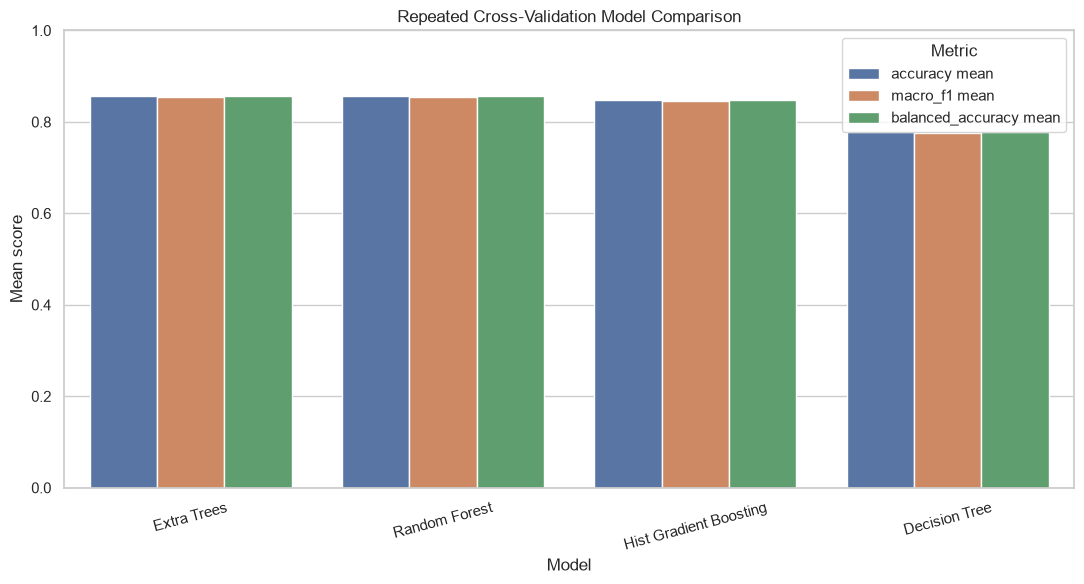

In [15]:
fig, ax = plt.subplots(figsize=(11, 6))
plot_data = cv_results.melt(
    id_vars="Model",
    value_vars=["accuracy mean", "macro_f1 mean", "balanced_accuracy mean"],
    var_name="Metric", value_name="Mean score"
)
sns.barplot(data=plot_data, x="Model", y="Mean score", hue="Metric", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Repeated Cross-Validation Model Comparison")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(CHARTS / "07_cross_validation_comparison.png", dpi=180, bbox_inches="tight")
plt.show()


## 12. Revised stratified holdout and hyperparameter tuning

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=2026, stratify=y
)

print("Training records:", len(X_train))
print("Holdout records:", len(X_test))
print("\nTraining class counts:")
display(y_train.value_counts().sort_index().to_frame("Training records"))
print("\nHoldout class counts:")
display(y_test.value_counts().sort_index().to_frame("Holdout records"))


Training records: 12096
Holdout records: 3024

Training class counts:


,Training records
Cover_Type,
1,1728
2,1728
3,1728
4,1728
5,1728
6,1728
7,1728



Holdout class counts:


,Holdout records
Cover_Type,
1,432
2,432
3,432
4,432
5,432
6,432
7,432


### Holdout interpretation

A new stratified 80:20 split is created for the revised tuning and final evaluation workflow. Hyperparameter selection uses only the training portion of this split. However, because the full dataset was used in previous project iterations, this holdout is not historically untouched. The repeated cross-validation results and this historical limitation must both be considered when interpreting performance.


In [17]:
tuning_pipeline = Pipeline([
    ("model", ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=1))
])

parameter_distributions = {
    "model__n_estimators": [150, 200, 250, 300],
    "model__max_depth": [None, 25, 35, 45],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", 0.5]
}

search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=parameter_distributions,
    n_iter=8,
    scoring="f1_macro",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:")
display(search.best_params_)
print("Best training CV macro F1:", round(search.best_score_, 5))


Fitting 3 folds for each of 8 candidates, totalling 24 fits


Best parameters:


{'model__n_estimators': 300,
 'model__min_samples_split': 2,
 'model__min_samples_leaf': 1,
 'model__max_features': 0.5,
 'model__max_depth': None}

Best training CV macro F1: 0.85926


In [18]:
tuning_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
tuning_results.to_csv(REPORTS / "extra_trees_tuning_results.csv", index=False)
display(tuning_results[[
    "rank_test_score", "mean_test_score", "std_test_score",
    "mean_train_score", "params"
]].head(8))


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
1,1,0.859264,0.009294,1.000000,"{'model__n_estimators': 300, 'model__min_sampl..."
2,2,0.858270,0.009800,1.000000,"{'model__n_estimators': 150, 'model__min_sampl..."
6,3,0.848399,0.010354,0.992054,"{'model__n_estimators': 250, 'model__min_sampl..."
0,4,0.828621,0.012363,0.938507,"{'model__n_estimators': 150, 'model__min_sampl..."
7,5,0.816446,0.014411,0.940512,"{'model__n_estimators': 250, 'model__min_sampl..."
5,6,0.793631,0.013544,0.889422,"{'model__n_estimators': 300, 'model__min_sampl..."
3,7,0.777945,0.011192,0.846626,"{'model__n_estimators': 250, 'model__min_sampl..."
4,8,0.760778,0.015986,0.819395,"{'model__n_estimators': 150, 'model__min_sampl..."


## 13. Final holdout evaluation

In [19]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Macro F1": f1_score(y_test, y_pred, average="macro"),
    "Weighted F1": f1_score(y_test, y_pred, average="weighted"),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred)
}

final_metrics_df = pd.DataFrame(
    [{"Metric": k, "Score": v} for k, v in final_metrics.items()]
)
display(final_metrics_df.round(5))
final_metrics_df.to_csv(REPORTS / "final_model_metrics.csv", index=False)

print("Classification report:")
report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).T
display(report_df.round(4))
report_df.to_csv(REPORTS / "classification_report.csv")


,Metric,Score
0,Accuracy,0.87566
1,Macro F1,0.87427
2,Weighted F1,0.87427
3,Balanced Accuracy,0.87566


Classification report:


,precision,recall,f1-score,support
1,0.7968,0.8079,0.8023,432.0000
2,0.8271,0.7199,0.7698,432.0000
3,0.8630,0.8310,0.8467,432.0000
4,0.9396,0.9722,0.9556,432.0000
5,0.8963,0.9606,0.9274,432.0000
6,0.8407,0.8796,0.8597,432.0000
7,0.9583,0.9583,0.9583,432.0000
accuracy,0.8757,0.8757,0.8757,0.8757
macro avg,0.8746,0.8757,0.8743,3024.0000
weighted avg,0.8746,0.8757,0.8743,3024.0000


## 14. Confusion matrix and class-level error analysis

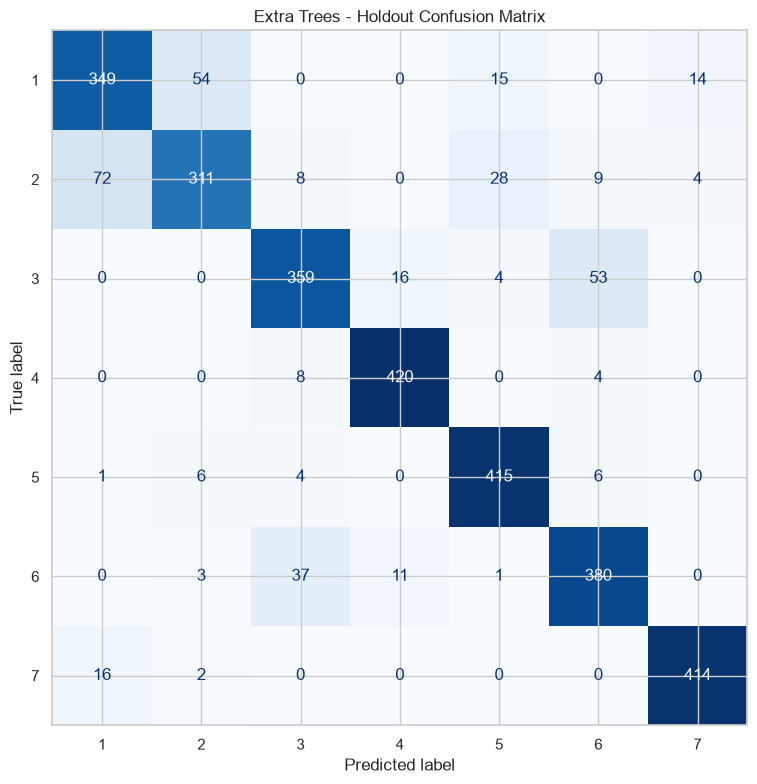

,Cover Type,Correct predictions,Incorrect predictions,Recall
0,1,349,83,0.8079
1,2,311,121,0.7199
2,3,359,73,0.8310
3,4,420,12,0.9722
4,5,415,17,0.9606
5,6,380,52,0.8796
6,7,414,18,0.9583


,Actual class,Predicted class,Misclassified records
3,2,1,72
0,1,2,54
10,3,6,53
18,6,3,37
5,2,5,28
8,3,4,16
21,7,1,16
1,1,5,15
2,1,7,14
19,6,4,11


In [20]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title("Extra Trees - Holdout Confusion Matrix")
plt.tight_layout()
plt.savefig(CHARTS / "08_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

class_errors = []
for i, label in enumerate(labels):
    row_total = cm[i].sum()
    correct = cm[i, i]
    class_errors.append({
        "Cover Type": label,
        "Correct predictions": int(correct),
        "Incorrect predictions": int(row_total - correct),
        "Recall": correct / row_total if row_total else np.nan
    })

class_error_df = pd.DataFrame(class_errors)
display(class_error_df.round(4))
class_error_df.to_csv(REPORTS / "class_error_analysis.csv", index=False)

off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
confusion_pairs = []
for i, actual in enumerate(labels):
    for j, predicted in enumerate(labels):
        if off_diagonal[i, j] > 0:
            confusion_pairs.append({
                "Actual class": actual,
                "Predicted class": predicted,
                "Misclassified records": int(off_diagonal[i, j])
            })
confusion_pairs_df = pd.DataFrame(confusion_pairs).sort_values(
    "Misclassified records", ascending=False
)
display(confusion_pairs_df.head(15))
confusion_pairs_df.to_csv(REPORTS / "most_common_class_confusions.csv", index=False)


### Error analysis interpretation

The confusion matrix shows correct and incorrect predictions for each actual and predicted class. Class-level recall identifies classes for which the model misses a larger proportion of observations. The most frequent off-diagonal pairs identify which cover types are most often confused. These results should guide any future feature engineering or data collection.


## 15. Model interpretation: impurity and permutation importance

,Feature,Impurity importance
0,Elevation,0.23392
5,Horizontal_Distance_To_Roadways,0.07744
13,Wilderness_Area4,0.07553
9,Horizontal_Distance_To_Fire_Points,0.06508
3,Horizontal_Distance_To_Hydrology,0.06084
4,Vertical_Distance_To_Hydrology,0.04616
6,Hillshade_9am,0.03964
1,Aspect,0.03918
7,Hillshade_Noon,0.03780
8,Hillshade_3pm,0.03320


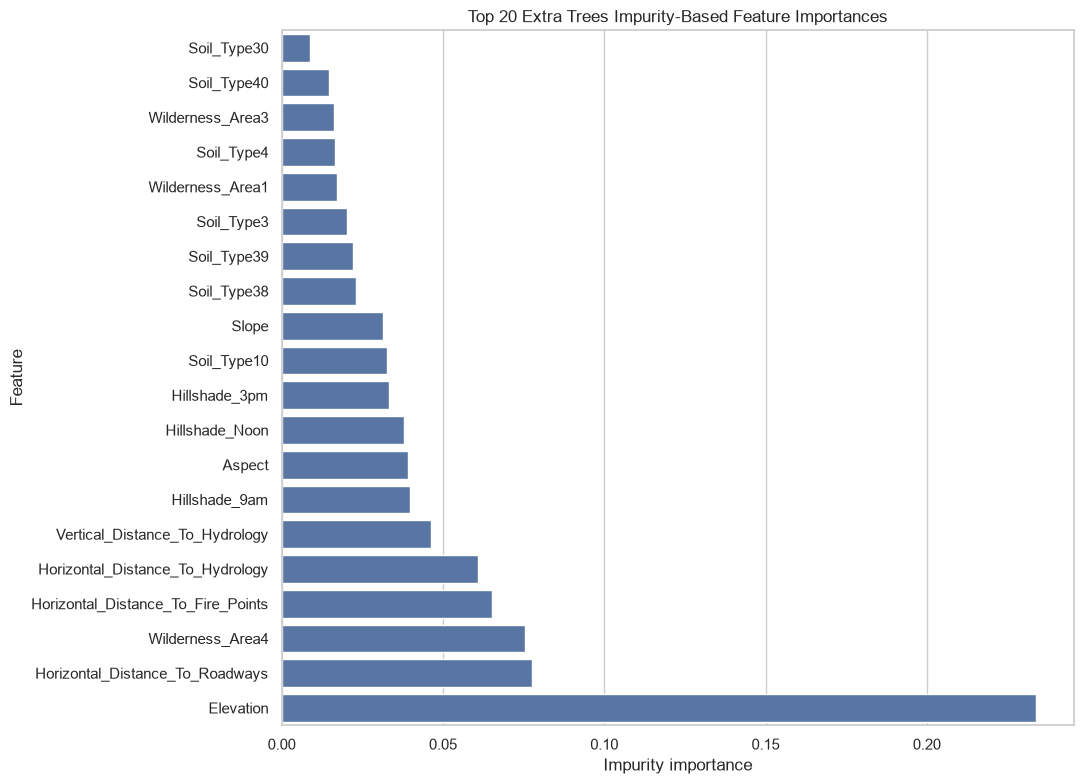

In [21]:
fitted_forest = best_model.named_steps["model"]
impurity_importance = pd.DataFrame({
    "Feature": X.columns,
    "Impurity importance": fitted_forest.feature_importances_
}).sort_values("Impurity importance", ascending=False)

display(impurity_importance.head(20).round(5))
impurity_importance.to_csv(REPORTS / "feature_importance.csv", index=False)

top_impurity = impurity_importance.head(20).sort_values("Impurity importance")
fig, ax = plt.subplots(figsize=(11, 8))
sns.barplot(data=top_impurity, x="Impurity importance", y="Feature", ax=ax)
ax.set_title("Top 20 Extra Trees Impurity-Based Feature Importances")
plt.tight_layout()
plt.savefig(CHARTS / "09_impurity_feature_importance.png", dpi=180, bbox_inches="tight")
plt.show()


,Feature,Permutation importance mean,Permutation importance std
0,Elevation,0.38765,0.00715
13,Wilderness_Area4,0.20807,0.00690
5,Horizontal_Distance_To_Roadways,0.08557,0.00260
9,Horizontal_Distance_To_Fire_Points,0.05858,0.00280
3,Horizontal_Distance_To_Hydrology,0.04755,0.00160
16,Soil_Type3,0.04415,0.00080
22,Soil_Type10,0.02748,0.00072
17,Soil_Type4,0.02584,0.00081
49,Soil_Type38,0.01956,0.00141
50,Soil_Type39,0.01593,0.00078


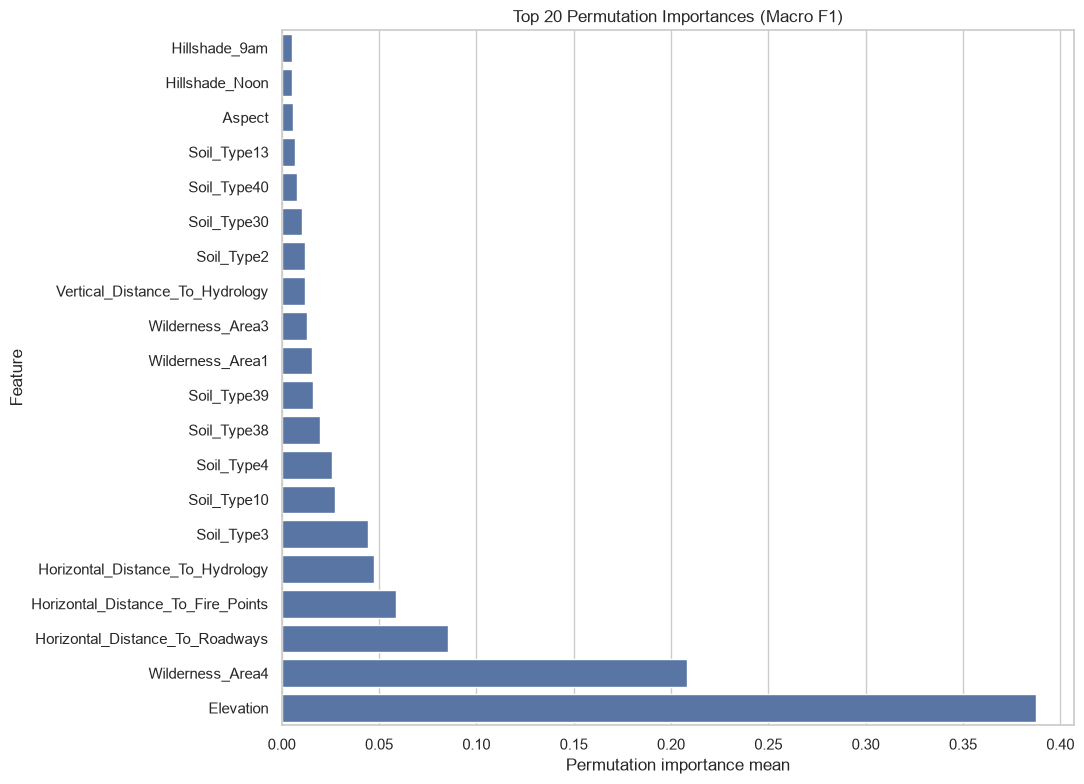

In [22]:
permutation = permutation_importance(
    best_model, X_test, y_test,
    scoring="f1_macro", n_repeats=3,
    random_state=RANDOM_STATE, n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X.columns,
    "Permutation importance mean": permutation.importances_mean,
    "Permutation importance std": permutation.importances_std
}).sort_values("Permutation importance mean", ascending=False)

display(permutation_df.head(20).round(5))
permutation_df.to_csv(REPORTS / "permutation_importance.csv", index=False)

top_perm = permutation_df.head(20).sort_values("Permutation importance mean")
fig, ax = plt.subplots(figsize=(11, 8))
sns.barplot(data=top_perm, x="Permutation importance mean", y="Feature", ax=ax)
ax.set_title("Top 20 Permutation Importances (Macro F1)")
plt.tight_layout()
plt.savefig(CHARTS / "10_permutation_importance.png", dpi=180, bbox_inches="tight")
plt.show()


### Feature importance interpretation

Impurity-based importance measures how much a feature contributes to splitting decisions within the fitted trees. It can favour variables with particular characteristics and can distribute importance across correlated predictors.

Permutation importance measures the reduction in a selected validation score when a feature's values are shuffled. Here the scoring metric is macro F1. Both measures describe model behaviour; neither establishes that a feature causes a forest cover type.


## 16. Save the model and project outputs

In [23]:
model_path = MODELS / "extra_trees_forest_cover.joblib"
joblib.dump(best_model, model_path)

feature_schema = {
    "feature_names": list(X.columns),
    "target_name": target_col,
    "excluded_columns": excluded_columns,
    "model_type": "ExtraTreesClassifier inside scikit-learn Pipeline"
}
joblib.dump(feature_schema, MODELS / "feature_schema.joblib")

print("Saved model:", model_path)
print("Model size (MB):", round(model_path.stat().st_size / (1024 * 1024), 2))
print("Saved feature schema:", MODELS / "feature_schema.joblib")
print("\nGenerated report files:")
for path in sorted(REPORTS.glob("*")):
    if path.is_file():
        print(path.name, "-", path.stat().st_size, "bytes")
print("\nGenerated charts:")
for path in sorted(CHARTS.glob("*.png")):
    print(path.name, "-", path.stat().st_size, "bytes")


Saved model: C:\Rakesh Project\Forest-Cover-Prediction\models\extra_trees_forest_cover.joblib
Model size (MB): 227.46
Saved feature schema: C:\Rakesh Project\Forest-Cover-Prediction\models\feature_schema.joblib

Generated report files:
class_error_analysis.csv - 265 bytes
classification_report.csv - 734 bytes
cross_validation_model_comparison.csv - 753 bytes
extra_trees_tuning_results.csv - 3739 bytes
feature_importance.csv - 1879 bytes
final_model_metrics.csv - 140 bytes
Forest_Cover_Prediction_Final_Report.pdf - 1905617 bytes
model_comparison.csv - 287 bytes
model_metrics.csv - 94 bytes
most_common_class_confusions.csv - 223 bytes
outlier_summary.csv - 785 bytes
permutation_importance.csv - 2647 bytes

Generated charts:
01_target_distribution.png - 44902 bytes
02_indicator_frequency.png - 196616 bytes
03_numeric_feature_distributions.png - 504682 bytes
04_continuous_feature_correlation.png - 280599 bytes
05_feature_target_median_heatmap.png - 185178 bytes
06_elevation_by_cover_type.p

## 17. Conclusions, limitations and future work

In [24]:
best_cv_row = cv_results.iloc[0]
lowest_recall_row = class_error_df.sort_values("Recall").iloc[0]
top_impurity_feature = impurity_importance.iloc[0]["Feature"]
top_perm_feature = permutation_df.iloc[0]["Feature"]

print("CONCLUSION")
print(f"- Best default candidate by mean CV macro F1: {best_cv_row['Model']}.")
print(f"- Mean CV macro F1: {best_cv_row['macro_f1 mean']:.4f} "
      f"(standard deviation: {best_cv_row['macro_f1 std']:.4f}).")
print(f"- Tuned Extra Trees holdout accuracy: {final_metrics['Accuracy']:.4f}.")
print(f"- Tuned Extra Trees holdout macro F1: {final_metrics['Macro F1']:.4f}.")
print(f"- Lowest-recall class in this holdout: {int(lowest_recall_row['Cover Type'])} "
      f"(recall: {lowest_recall_row['Recall']:.4f}).")
print(f"- Highest impurity importance: {top_impurity_feature}.")
print(f"- Highest permutation importance: {top_perm_feature}.")

print("\nLIMITATIONS")
print("- The dataset was used in earlier project iterations; the revised holdout is not historically untouched.")
print("- Cross-validation scores are internal estimates on this dataset, not external geographic validation.")
print("- The dataset contains 15,120 records and may not represent every forest region or condition.")
print("- Feature importance describes model behaviour and does not establish causation.")
print("- Model performance may change when applied to data collected under different conditions.")

print("\nFUTURE WORK")
print("- Evaluate on a genuinely new dataset collected independently of this project.")
print("- Investigate the most frequent class-confusion pairs.")
print("- Compare additional algorithms and carefully justified feature engineering.")
print("- Assess performance across geographic regions and different data collection conditions.")


CONCLUSION
- Best default candidate by mean CV macro F1: Extra Trees.
- Mean CV macro F1: 0.8554 (standard deviation: 0.0038).
- Tuned Extra Trees holdout accuracy: 0.8757.
- Tuned Extra Trees holdout macro F1: 0.8743.
- Lowest-recall class in this holdout: 2 (recall: 0.7199).
- Highest impurity importance: Elevation.
- Highest permutation importance: Elevation.

LIMITATIONS
- The dataset was used in earlier project iterations; the revised holdout is not historically untouched.
- Cross-validation scores are internal estimates on this dataset, not external geographic validation.
- The dataset contains 15,120 records and may not represent every forest region or condition.
- Feature importance describes model behaviour and does not establish causation.
- Model performance may change when applied to data collected under different conditions.

FUTURE WORK
- Evaluate on a genuinely new dataset collected independently of this project.
- Investigate the most frequent class-confusion pairs.
- C

## 18. Reproducibility and final checks

The notebook saves the fitted pipeline, feature schema, cross-validation results, tuning results, final metrics, classification report, class error analysis, feature importance tables and charts under the project folders.

For deployment or future inference, input data must contain the same predictor columns in the same logical schema used during training. The identifier and target must not be supplied as model predictors.
